In [1]:
%load_ext autoreload
%autoreload 2

import sys
import os

# Dodanie katalogu nadrzędnego do ścieżki systemowej, aby Python widział folder 'src'
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

from src.data_loader import fetch_and_prepare_options


df, S, target_expiry = fetch_and_prepare_options("SPY")

In [2]:
import os
import sys

print("Working directory:", os.getcwd())
print("Python executable:", sys.executable)
print("Files:", os.listdir())

Working directory: /Users/aleksy/1_Code/3_Projects/options-pricing-and-volatility/notebooks
Python executable: /Users/aleksy/.pyenv/versions/env06/bin/python
Files: ['main_analysis.ipynb']


In [3]:
X = df[['Moneyness']]
y = df['IV']

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
model = LinearRegression()
model.fit(X_poly, y)

X_plot = pd.DataFrame({'Moneyness': np.linspace(X['Moneyness'].min(), X['Moneyness'].max(), 100)})
X_plot_poly = poly.transform(X_plot)
y_plot = model.predict(X_plot_poly)

constant_iv = y.mean()
mse_vs_constant = np.mean((y - constant_iv)**2)
mse_vs_model = np.mean((y - model.predict(X_poly))**2)

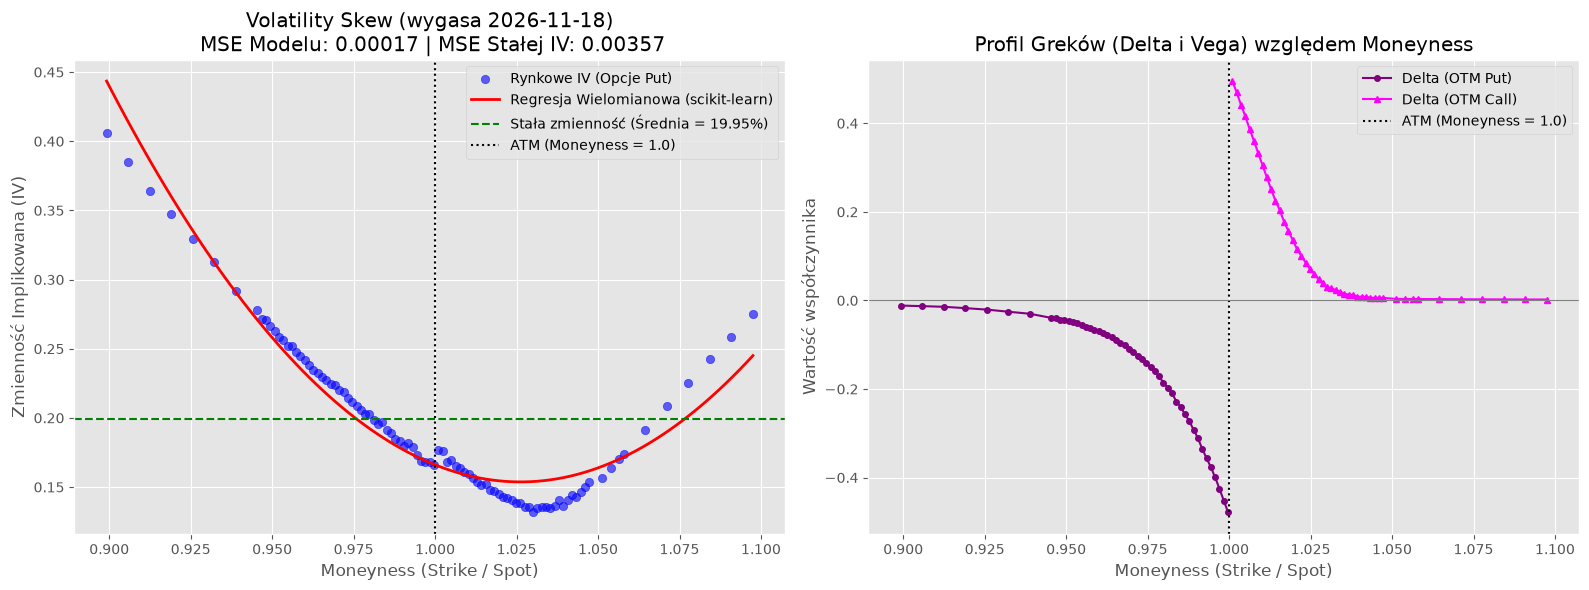

In [7]:
plt.style.use('ggplot')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel lewy: Volatility Skew
ax1.scatter(df['Moneyness'], df['IV'], color='blue', alpha=0.6, label='Rynkowe IV (Opcje Put)')
ax1.plot(X_plot['Moneyness'], y_plot, color='red', linewidth=2, label='Regresja Wielomianowa (scikit-learn)')
ax1.axhline(constant_iv, color='green', linestyle='--', label=f'Stała zmienność (Średnia = {constant_iv:.2%})')
ax1.axvline(1.0, color='black', linestyle=':', label='ATM (Moneyness = 1.0)')
ax1.set_title(f'Volatility Skew (wygasa {target_expiry})\n MSE Modelu: {mse_vs_model:.5f} | MSE Stałej IV: {mse_vs_constant:.5f}')
ax1.set_xlabel('Moneyness (Strike / Spot)')
ax1.set_ylabel('Zmienność Implikowana (IV)')
ax1.legend()
# Rozdzielenie rysowania Delty na Put i Call, aby usunąć pionowy skok na wykresie
df_puts = df[df['option_type'] == 'put']
df_calls = df[df['option_type'] == 'call']

ax2.plot(df_puts['Moneyness'], df_puts['Delta'], color='purple', marker='o', markersize=4, label='Delta (OTM Put)')
ax2.plot(df_calls['Moneyness'], df_calls['Delta'], color='magenta', marker='^', markersize=4, label='Delta (OTM Call)')
ax2.axvline(1.0, color='black', linestyle=':', label='ATM (Moneyness = 1.0)')
ax2.axhline(0, color='gray', linewidth=0.8)
ax2.set_title('Profil Greków (Delta i Vega) względem Moneyness')
ax2.set_xlabel('Moneyness (Strike / Spot)')
ax2.set_ylabel('Wartość współczynnika')
ax2.legend()

plt.tight_layout()
plt.show()